In [129]:
import numpy as np
import matplotlib.pyplot as plt
import math
import pandas as pd


# The Birthday Paradox Project #


## Introduction ##

### Explaining the paradox ###
The birthday paradox is called a paradox due to how unlikely the answer is to the human mind. The paradox asks the question of what is the minimum number of people in a room so that there is at least 50% chance that 2 of them share a birthday. The paradox itself is counterintuitive, however it is perfectly logical which will be shown below.

Usually people look at this from their own perspective and guess that you need a minimum of 183 people. That is rounded half of the days of the year. However, this approach is incorrect as you would only compare all people against one person. Instead, the correct approach is to compare everyone against each other before a conclusion is drawn.

### The Math ###

The easiest approach is to subtract the probability of unique birthdays from one. Let's start by adding people in the room one by one. It must be stated that we assume the year has 365 days, and we are currently not considering leap years.
Let the number of people be expressed as n.

First person: the probability of them having a unique birthday is equal to one, there are no other people to coincide with:

$$ \frac{365}{365} = 1 $$

Second person: the probability of having a unique birthday drops because one of the 365 days is already taken by the first person, leaving 364 possible days:

$$ \frac{364}{365} \approx 0.997 $$

Third person: the probability continues to decrease as person 3 cannot have the same birthday as person 1 or 2:

$$ \frac{363}{365} \approx 0.995 $$

Person n: when person n enters the room we need to follow the same pattern:

$$ \frac{365 - n + 1}{365} $$

Therefore, to calculate the probability of a unique birthday we must multiply the individual probabilities as they are happening in a sequence until we get to the n person. Let's also define a variable AU (all unique):

$$ P(AU) = \frac{365}{365} \times \frac{364}{365} \times \frac{363}{365} \times ... \times \frac{365 - n + 1}{365} $$

We should simplify the equation to:

$$ P(AU) = \frac{365\times364\times363\times...\times(365-n+1)}{365^n}   $$

Finally, in order to get the probability of having a matching birthday we need to subtract the probability for unique birthdays from 1:

$$ P(\overline{AU}) = 1 - \frac{365\times364\times363\times...\times(365-n+1)}{365^n}   $$


Now that we have expressed the probability of having a matching birthday, let's write a function in Python which when given a number of people calculates the probability of a pair sharing a birthday:

In [130]:
def calculate_birthday_probability(n):
     # Since the range function has an exclusive limit, this forces us to drop the "1" from the expression (365 - n + 1)
    not_the_same_birthday = math.prod(x / 365 for x in range(365, 365 - n, -1))
    return 1 - not_the_same_birthday

Note: If we try to write the function in Python like the simplified mathematical manner:



In [131]:
# def calculate_birthday_probability(n):  # Feel free to remove the commented out lines to test this
#     not_the_same_birthday = math.prod([x for x in range(365, 365 - n, -1)]) / 365**n
#     return 1 - not_the_same_birthday

We will run into one of the Python restrictions. In order to complete a division Python has to transform the integers into floats before executing the division. Once we get to n >= 121 we start running into an Overflow Error as the Python floats hit their limit of 1.8 * 10^308. We need to be smart when writing code and ensure we do not hit the built-in Python limits so that the function works correctly.

### The Graph ###

Let's plot the function and see how the probability changes as the size of the group of people increases.

While there are 365 days in a non-leap year, for better visualisation I suggest we limit the plotting of x to a maximum of 100 people in a group. Once we hit more than 70 people in a group, it will become obvious that the probability is getting very close to 1, so there is no need to plot the probabilities over 100 people.

We are using points instead of a continuous line as we cannot represent 2.5 people (Even after watching the show "Two and a half men" :-)

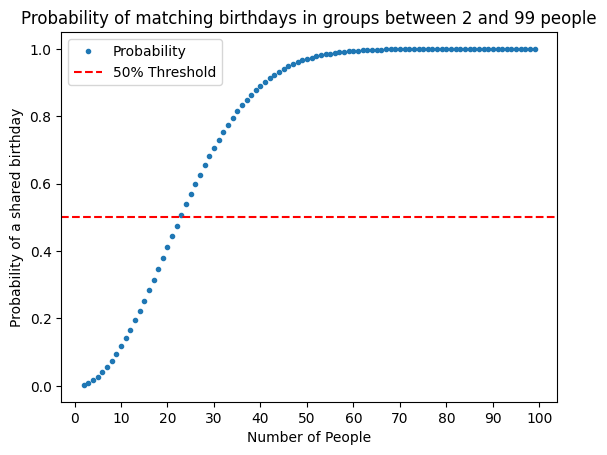

In [132]:
x = np.arange(2, 100)
probabilities = [calculate_birthday_probability(n) for n in x]

plt.plot(x, probabilities, "o", markersize = 3, label="Probability")
plt.title(f"Probability of matching birthdays in groups between {x.min()} and {x.max()} people")
plt.xlabel("Number of People")
plt.ylabel("Probability of a shared birthday")
plt.axhline(0.5, linestyle="--", color="red", label="50% Threshold")
plt.xticks(np.arange(0, x.max()+10, 10))
plt.legend()
plt.show()

To give an answer to the question of the Birthday Paradox, visually from the graph it looks like the answer lies somewhere between 20 and 25, let's test the function for those values:

In [133]:
for i in range(20, 26):
    print(f"Number of people: {i}. Probability of shared birthday: {round(calculate_birthday_probability(i), 4):.5f}")

Number of people: 20. Probability of shared birthday: 0.41140
Number of people: 21. Probability of shared birthday: 0.44370
Number of people: 22. Probability of shared birthday: 0.47570
Number of people: 23. Probability of shared birthday: 0.50730
Number of people: 24. Probability of shared birthday: 0.53830
Number of people: 25. Probability of shared birthday: 0.56870


The final answer is 23 people. As stated above the answer is counterintuitive to the human mind, however it is still perfectly logical as already shown.

## The Simulation ##

### Randomly Generated Birthdays ###

 We have theoretically concluded that we need 23 people to have 50% chance or more to find a matching birthday. The natural next step in this project is to create an *n* number of people with random birthdays then search for a matching birthday.

Let's first create a function that randomly generates an *n* number of people. When we are generating the function and not using real data yet, there is no need to generate a day and a month separately. We can use the range between 1 and 365 days and generate the birthday in this way:

In [134]:
def generate_group(n: int):
    return np.random.randint(1, 366, size = n)

The next step is to write the function that checks whether there is a matching birthday:

In [135]:
def has_matching_birthday(people: list) -> bool:
    not_matching_birthdays_people_list = []
    for person in range(len(people)):
        if people[person] not in not_matching_birthdays_people_list:
            not_matching_birthdays_people_list.append(people[person])
        else:
            return True
    return False

Next, we need to generate a *n_g* number of groups and run the simulation over them while recording whether there is a matching birthday in the group or not:

In [136]:
def run_random_simulation(n, n_g):
    counter = [0, 0] # first index records the groups without matches, while the second index records the groups with birthday matches
    for _ in range(n_g):
        people = generate_group(n)
        if has_matching_birthday(people):
            counter[1] += 1
        else:
            counter[0] += 1
    return counter

n = 23 #We are keeping the number of group members that generate the 50% chance
n_g = 100 #First try is with 100 groups

c = run_random_simulation(n, n_g)

print(f"Number of groups with matching birthdays: {c[1]}\n"
      f"Number of groups without a matching birthday: {c[0]}")


Number of groups with matching birthdays: 53
Number of groups without a matching birthday: 47


The above is the basic code to evaluate a random number of birthdays in a group of 23 people, ran 100 times. We can test this code on a number of occasions and will get various results sometimes close to the expected probability of 50% and other times there will be a significant difference.

The more precise number is 50.730% which is the theoretical value of the formula. However, we won't be able to get this result when we are only testing 100 groups of people.

The next step is to repeat this experiment 1000 times, each time recording how many of the n_g groups contain a matching birthday. We expect the results to form a bell-shaped (Gaussian) distribution centred around n_g × 50.73%, which is about 51 groups when n_g = 100.

Theoretical probability:     0.50730
Average overall probability: 0.50762


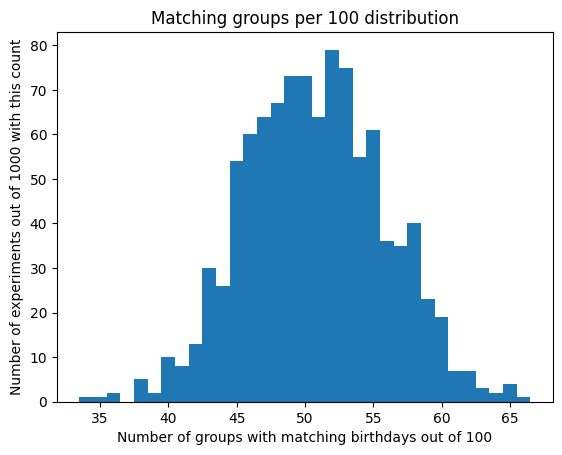

In [137]:
number_of_runs = 1000
matching_groups_sum = 0
list_of_matching_groups = []
for _ in range(number_of_runs):
    matching_groups = run_random_simulation(n, n_g)[1]
    matching_groups_sum += matching_groups
    list_of_matching_groups.append(matching_groups)

average_probability = matching_groups_sum / (number_of_runs * n_g)
print(f"Theoretical probability:     {calculate_birthday_probability(n):.5f}")
print(f"Average overall probability: {average_probability:.5f}")

plt.hist(list_of_matching_groups, bins = np.arange(min(list_of_matching_groups) - 0.5, max(list_of_matching_groups) + 1))
plt.xlabel(f"Number of groups with matching birthdays out of {n_g}")
plt.ylabel(f"Number of experiments out of {number_of_runs} with this count")
plt.title(f"Matching groups per {n_g} distribution")
plt.show()


### Real Dataset of Birthdays ###

The next step of this project is to find a real data set of birthdays and use that data to test the Birthday Paradox, observe and write down the results.

The dataset I found is from the following website: https://www.kaggle.com/datasets/ulrikthygepedersen/birthdays?resource=download accessed and downloaded on 14.11.2026 at 7:10 pm. The file has been uploaded to the GitHub repository.

Before we start dissecting the dataset, I would make a few points and observations. The dataset has 5 columns: <br>
A = year <br>
B = month <br>
C = day of the month <br>
D = day of the week <br>
E = number of births <br>

Please note that up until now when evaluating the Birthday paradox we have only dealt with two parameters: month and day. To make things easier we even used one variable that was merged from the day and month. This dataset presents two new parameters: year and day of the week. We will see in due time how these two can impact our experiments and what conclusions we can draw from the addition of these parameters

When we open the dataset file it becomes immediately clear that we can visually observe a trend. The total number of births on the 6th and 7th day of the week, that is Saturday and Sunday, is significantly lower than the births during the rest of the week. In the *"Neonatal mortality in weekend vs weekday births"*,  Gould, J. B., Qin, C., Marks, A. R., & Chavez, G. (2003), it is stated that:

*"Many physicians prefer to induce labor in women whose fetuses are at risk, but healthy enough for delivery, during the week when ample support staff is available. The same is true of cesarean sections, which were used to deliver about 20 percent of the infants in the study. This tendency to favor weekdays is reflected in the fact that **there were 17.5 percent fewer births on the weekend** than would have been expected had the births been distributed randomly."*  (emphasis added)

We will test whether this change in births rate during weekends affects us and report the results. However, before that let's do a small side step and quickly check whether the quoted statement above holds for our data set:

In [138]:
df = pd.read_csv("kaggle_birthdays_data.csv")

# #Testing panda functions are working correctly:
# print(f"Head:\n{df.head()} ")                                 # the first 5 rows
# print(f"Shape:\n{df.shape}")                                  # (number of rows, number of columns)
# print("Info:\n")
# df.info()                                                     # column names, types, and non-missing counts
# print(f"Describe:\n{df.describe()}")                          # min, max and mean of every numeric column
# print(f"Missing values per column:\n{df.isna().sum()}")       # missing values per column
# print(f"Number of duplicate rows:\n{df.duplicated().sum() }\n") # number of duplicate rows
# print("-----------------------------------------\n")


The above commented out code tests that the dataset is working correctly. Please feel free to remove the comments and test it.

In [139]:
average_births = df["births"].mean()
print(f"Average births per day: {average_births:.2f}")

weekend_births_df = df[df["day_of_week"] >= 6]
weekend_births = weekend_births_df["births"].mean()
print(f"Average birthday during the weekend: {weekend_births:.2f}")

print(f"Percentage of lower births during weekends compared to average births: {(100 - ((100 * weekend_births) / average_births)):.2f}")

Average Birthday per day: 11175.06
Average Birthday during the weekend: 8128.67
Percentage of lower births during weekends compared to average births: 27.26


Well this is surprising! The result that showed in the real data is 27.26% less births during weekends in comparison to the average births. The result from this dataset is vastly different from the expected result from the quoted paper above. However, the purpose of this part of the project is not to seek the underlying reasons for this difference but to check whether this difference would show up in the results of the functions.

Another variable worth mentioning is the leap year. We intentionally excluded the leap years in the earlier simulated tests. In the case with real data a leap year comes once every 4 years. So instead of having  1460 days every 4 years we would have 1461 days. The increase represents a negligible increase of 0.0684% in the days tested for a 4 year period. We will also intentionally exclude the leap year days from the dataset  in order to simplify the data and remove these edge cases.

In [140]:
df_new = df[~((df['month'] == 2) & (df['date_of_month'] == 29))].copy()
print(f"Number of original rows: {len(df)}")
print(f"Number of filtered rows: {len(df_new)}")

Number of original rows: 7670
Number of filtered rows: 7665


We can clearly show above that only the leap year days i.e. 29th February have been removed.

